In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
import seaborn as sns
from sklearn.metrics import balanced_accuracy_score
from imblearn.metrics import geometric_mean_score

In [43]:
androgen_data = pd.read_csv('https://raw.githubusercontent.com/krtka2012/qsar_projectML/refs/heads/main/qsar_androgen_receptor.csv', header=None, sep=';')

In [44]:
androgen_data

,0,1,2,3,4,5,6,7,8,9,...,1015,1016,1017,1018,1019,1020,1021,1022,1023,1024
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,positive
1,0,0,0,0,0,0,1,0,0,0,...,0,0,1,0,0,0,1,0,0,positive
2,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,positive
3,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,positive
4,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1682,0,0,1,0,0,0,0,1,0,1,...,0,0,1,0,0,0,0,1,0,negative
1683,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,negative
1684,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,negative
1685,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,negative


In [45]:
print(androgen_data.shape)
print(androgen_data.head())

(1687, 1025)
   0     1     2     3     4     5     6     7     8     9     ...  1015  \
0     0     0     0     0     0     0     0     0     0     0  ...     0   
1     0     0     0     0     0     0     1     0     0     0  ...     0   
2     0     0     1     0     0     0     0     0     0     0  ...     0   
3     0     0     1     0     0     0     0     0     0     0  ...     0   
4     0     0     1     0     0     0     0     0     0     0  ...     0   

   1016  1017  1018  1019  1020  1021  1022  1023      1024  
0     0     0     0     0     0     0     0     0  positive  
1     0     1     0     0     0     1     0     0  positive  
2     0     0     0     0     0     0     0     0  positive  
3     0     0     0     0     0     0     0     0  positive  
4     0     0     0     0     0     0     0     1  positive  

[5 rows x 1025 columns]


In [46]:
androgen_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1687 entries, 0 to 1686
Columns: 1025 entries, 0 to 1024
dtypes: int64(1024), str(1)
memory usage: 13.2 MB


In [47]:
androgen_data.describe()

,0,1,2,3,4,5,6,7,8,9,...,1014,1015,1016,1017,1018,1019,1020,1021,1022,1023
count,1687.000000,1687.000000,1687.000000,1687.000000,1687.000000,1687.000000,1687.000000,1687.000000,1687.000000,1687.000000,...,1687.000000,1687.000000,1687.000000,1687.000000,1687.000000,1687.000000,1687.000000,1687.000000,1687.000000,1687.000000
mean,0.064612,0.013634,0.062833,0.024303,0.061055,0.010670,0.052756,0.056313,0.011263,0.094250,...,0.082395,0.026082,0.071725,0.200948,0.180794,0.024896,0.022525,0.033788,0.033788,0.066983
std,0.245912,0.115999,0.242735,0.154035,0.239502,0.102773,0.223613,0.230593,0.105557,0.292263,...,0.275047,0.159426,0.258108,0.400828,0.384962,0.155855,0.148428,0.180736,0.180736,0.250066
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [48]:
androgen_data.isnull().sum()

0       0
1       0
2       0
3       0
4       0
       ..
1020    0
1021    0
1022    0
1023    0
1024    0
Length: 1025, dtype: int64

In [49]:
androgen_data[1024].value_counts()

1024
negative    1488
positive     199
Name: count, dtype: int64

In [50]:
androgen_data[1024] = (
    androgen_data[1024]
    .replace({"negative": 0, "positive": 1})
    .astype(int)
)

In [51]:
print(androgen_data.head())

   0     1     2     3     4     5     6     7     8     9     ...  1015  \
0     0     0     0     0     0     0     0     0     0     0  ...     0   
1     0     0     0     0     0     0     1     0     0     0  ...     0   
2     0     0     1     0     0     0     0     0     0     0  ...     0   
3     0     0     1     0     0     0     0     0     0     0  ...     0   
4     0     0     1     0     0     0     0     0     0     0  ...     0   

   1016  1017  1018  1019  1020  1021  1022  1023  1024  
0     0     0     0     0     0     0     0     0     1  
1     0     1     0     0     0     1     0     0     1  
2     0     0     0     0     0     0     0     0     1  
3     0     0     0     0     0     0     0     0     1  
4     0     0     0     0     0     0     0     1     1  

[5 rows x 1025 columns]


In [52]:
X = androgen_data.drop(columns=1024)
y = androgen_data[1024]

In [53]:
print(X)
print(y)

      0     1     2     3     4     5     6     7     8     9     ...  1014  \
0        0     0     0     0     0     0     0     0     0     0  ...     0   
1        0     0     0     0     0     0     1     0     0     0  ...     1   
2        0     0     1     0     0     0     0     0     0     0  ...     0   
3        0     0     1     0     0     0     0     0     0     0  ...     0   
4        0     0     1     0     0     0     0     0     0     0  ...     0   
...    ...   ...   ...   ...   ...   ...   ...   ...   ...   ...  ...   ...   
1682     0     0     1     0     0     0     0     1     0     1  ...     0   
1683     0     0     0     0     0     0     0     0     0     0  ...     0   
1684     0     0     0     0     0     0     0     0     0     0  ...     0   
1685     0     0     1     0     0     0     0     0     0     0  ...     0   
1686     0     0     1     0     0     0     0     0     0     0  ...     0   

      1015  1016  1017  1018  1019  1020  1021  102

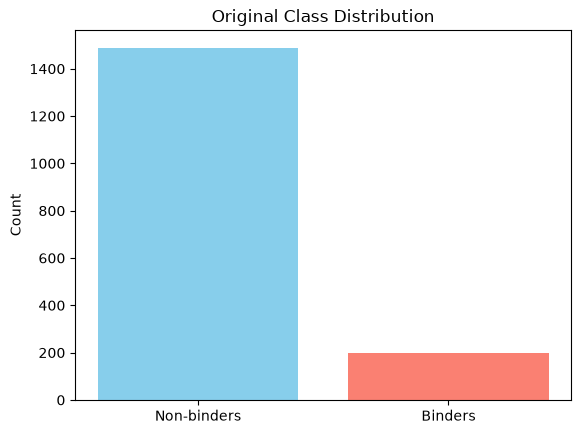

In [54]:
plt.bar(y.value_counts().index, y.value_counts().values, color=['skyblue','salmon'])
plt.xticks([0,1], ['Non-binders', 'Binders'])
plt.ylabel("Count")
plt.title("Original Class Distribution")
plt.show()

In [55]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [56]:
print(X.shape, X_train.shape, X_test.shape)

(1687, 1024) (1349, 1024) (338, 1024)


In [57]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [58]:
X_train_prediction = knn.predict(X_train)
training_data_accuracy = accuracy_score(X_train_prediction, y_train)
print('Accuracy for training data: ', training_data_accuracy)

Accuracy for training data:  0.9214232765011119


Test set Accuracy:  0.4911242603550296
Test set AUC:  0.6789429530201343
Test set G-mean:  0.6327870598291722
Test set Confusion Matrix:
 [[129 169]
 [  3  37]]
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.43      0.60       298
           1       0.18      0.93      0.30        40

    accuracy                           0.49       338
   macro avg       0.58      0.68      0.45       338
weighted avg       0.88      0.49      0.56       338



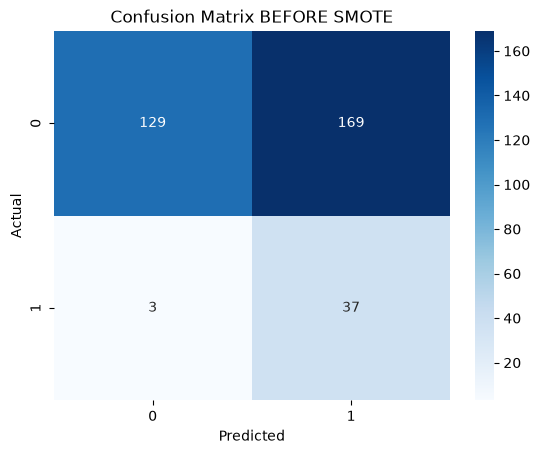

In [81]:
y_pred = knn.predict(X_test)
print("Test set Accuracy: ", accuracy_score(y_test, y_pred))
print("Test set AUC: ", balanced_accuracy_score(y_test, y_pred))
print("Test set G-mean: ", geometric_mean_score(y_test, y_pred))
print("Test set Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix BEFORE SMOTE")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

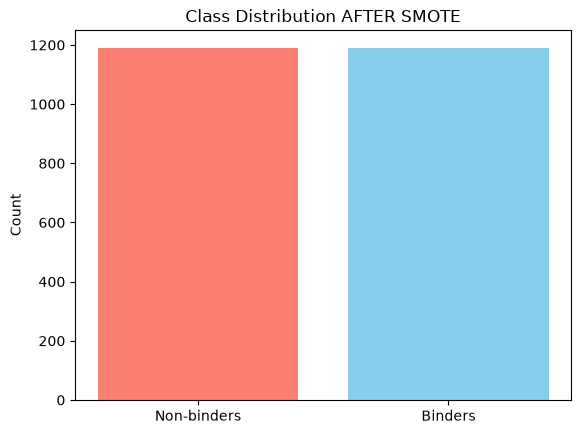

In [84]:
smote = SMOTE(sampling_strategy='minority', random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

plt.bar(y_train_sm.value_counts().index, y_train_sm.value_counts().values, 
        color=['skyblue','salmon'])
plt.xticks([0,1], ['Non-binders', 'Binders'])
plt.ylabel("Count")
plt.title("Class Distribution AFTER SMOTE")
plt.show()

In [78]:
print(X_train_sm.shape)
print(X_test.shape)

(2380, 1024)
(338, 1024)


Accuracy AFTER SMOTE: 49.41 %

Test set Confusion Matrix:
 [[130 168]
 [  3  37]]
Classification Report AFTER SMOTE:
               precision    recall  f1-score   support

           0       0.98      0.44      0.60       298
           1       0.18      0.93      0.30        40

    accuracy                           0.49       338
   macro avg       0.58      0.68      0.45       338
weighted avg       0.88      0.49      0.57       338



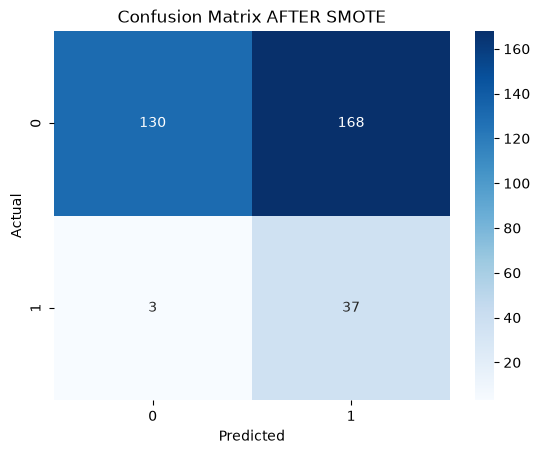

In [85]:
knn.fit(X_train_sm, y_train_sm)

y_pred_sm = knn.predict(X_test)

print("Accuracy AFTER SMOTE:", round(accuracy_score(y_test, y_pred_sm)*100, 2), "%\n")
print("Test set Confusion Matrix:\n", confusion_matrix(y_test, y_pred_sm))
print("Classification Report AFTER SMOTE:\n", classification_report(y_test, y_pred_sm))

sns.heatmap(confusion_matrix(y_test, y_pred_sm), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix AFTER SMOTE")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [86]:
input_data_df = X_test.iloc[[200]]

prediction = knn.predict(input_data_df)

print("Predicted:", prediction[0])
print("Actual:", y_test.iloc[200])

Predicted: 1
Actual: 0
